# CA2 Part A - TensorFlow Serving Deployment (ST1516)

**Student Name:** Goh Kun Ming

**Admin ID:** P2415691

**Module:** DevOps and Automation For AI

**ORCiD:** 0009-0008-7666-781X

**Render Status Links (single service):**
- VegNet-101: https://ca2-daaa2b02-p2415691-gohkunming.onrender.com/v1/models/vegnet-101
- VegNet-23: https://ca2-daaa2b02-p2415691-gohkunming.onrender.com/v1/models/vegnet-23


## Objective and Scope (Part A)
This notebook documents the deployment of two CNN vegetable classifiers (VegNet-101 and VegNet-23) for inference using TensorFlow Serving and Docker. A single Render service hosts both models via `models.config`. The workflow verifies local and remote inference and records assessment evidence.

Deliverables:
- SavedModel exports for both networks.
- Local TF Serving status and inference outputs.
- Render deployment status and inference outputs.


## Process Alignment (Checklist)
- Reuse trained weights from ST1504 and export SavedModel artifacts.
- Serve both models locally using `models.config`.
- Deploy one Render service using the Dockerfile.
- Validate status endpoints and top-3 predictions locally and remotely.


# 1. Libraries and Paths


This section enumerates required libraries and defines the project paths used for data, models, and exports.


In [1]:
import os
from pathlib import Path
import random
import shutil
import io
import base64
import numpy as np

# Silence TensorFlow/absl INFO and WARNING logs during export.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
try:
    from absl import logging as absl_logging
    absl_logging.set_verbosity("error")
    absl_logging.set_stderrthreshold("error")
except ImportError:
    pass

import tensorflow as tf

tf.get_logger().setLevel("ERROR")

from PIL import Image, ImageOps
from IPython.display import HTML, display

BASE_DIR = Path("../../").resolve()
DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"
TF_MODELS_DIR = BASE_DIR / "tf_models"

print("Base dir:", BASE_DIR)


Base dir: D:\DOAA\CA2-DAAA2B02-P2415691-GohKunMing\Source-Codes


The output confirms successful imports and path resolution. If an import fails, consult `model_serving/requirements.txt`.


## 1.1 Dataset Structure Check


This section validates the dataset directory structure by listing class folders under `data/train` and counting images across splits. The class order defines the label mapping for predictions.


In [2]:
classes = sorted([p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir()])
print("Classes:", classes)
for split in ["train", "validation", "test"]:
    paths = list((DATA_DIR / split).rglob("*.jpg"))
    print(f"{split}: {len(paths)} images")

Classes: ['Bean', 'Bitter_Gourd', 'Brinjal', 'Cabbage', 'Capsicum', 'Cauliflower and Broccoli', 'Cucumber and Bottle_Gourd', 'Potato', 'Pumpkin', 'Radish and Carrot', 'Tomato']
train: 7699 images
validation: 2200 images
test: 2200 images


Confirm that 11 classes are present and each split contains images; this mapping is used for inference outputs.


## 1.2 Model Architectures and Math


This section defines the two CNN architectures as trained and documents the underlying mathematics for key layers and objectives used during inference.

#### Architecture Summary and Rationale
- VegNet-101 uses 101x101x1 inputs to preserve texture detail.
- VegNet-23 uses 23x23x1 inputs for faster inference and lower compute.
- Both output a length-11 probability vector aligned to the class list above.

Design choices:
- Conv -> BatchNorm -> activation improves stability and feature learning.
- MaxPool after block 2 reduces spatial size while keeping mid-level features.
- Dropout and L2 regularization reduce overfitting.
- Global Average Pooling cuts parameter count before the Dense classifier.

#### Math Behind the CNN
Each equation is centered. Purpose is stated, followed by a legend for symbols.

**Convolution (feature extraction)**
Purpose: learn local patterns (edges, textures).

$$
y_{i,j,k} = \sum_{u=0}^{K-1} \sum_{v=0}^{K-1} \sum_{c=0}^{C-1} W_{u,v,c,k} x_{i+u, j+v, c} + b_k
$$

Legend:
- $x_{i,j,c}$: input feature at spatial position $(i,j)$ and channel $c$.
- $y_{i,j,k}$: output feature at position $(i,j)$ for output channel $k$.
- $W_{u,v,c,k}$: kernel weight at offset $(u,v)$ from input channel $c$ to output channel $k$.
- $b_k$: bias for output channel $k$.
- $K$: kernel size (here $K=3$), $C$: number of input channels.

**Batch Normalization (stabilization)**
Purpose: normalize activations to speed up convergence.

$$
\mathrm{BN}(x) = \gamma \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta
$$

Legend:
- $\mu$, $\sigma^2$: batch mean and variance.
- $\gamma$, $\beta$: learned scale and shift.
- $\epsilon$: small constant for numerical stability.

**Activation (non-linearity)**
Purpose: allow non-linear decision boundaries.

$$
\mathrm{ReLU}(x) = \max(0, x)
$$

$$
\mathrm{LeakyReLU}(x) = \max(ax, x)
$$

Legend:
- $a$: small slope for negative inputs.

**Max Pooling (downsampling)**
Purpose: reduce spatial size and add translation tolerance.

$$
y_{i,j,k} = \max_{(u,v) \in \mathcal{W}} x_{i+u, j+v, k}
$$

Legend:
- $\mathcal{W}$: pooling window (e.g., 2x2).

**Dropout (regularization)**
Purpose: prevent co-adaptation by randomly dropping units in training.

$$
y = \frac{m \odot x}{p}, \quad m \sim \mathrm{Bernoulli}(p)
$$

Legend:
- $m$: dropout mask, $p$: keep probability, $\odot$: element-wise product.

**Global Average Pooling (parameter reduction)**
Purpose: compress a spatial map into one value per channel.

$$
y_k = \frac{1}{H W} \sum_{i=1}^{H} \sum_{j=1}^{W} x_{i,j,k}
$$

Legend:
- $H$, $W$: height and width of the feature map.

#### Objective, Regularization, and Probabilities
**Softmax (convert logits to probabilities)**
Purpose: map logits to a normalized probability distribution.

$$
\hat{y}_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}
$$

Legend:
- $z_k$: logit for class $k$, $K=11$ classes.
- $\hat{y}_k$: predicted probability for class $k$.

**Sparse Categorical Cross-Entropy (classification loss)**
Purpose: penalize incorrect predictions using the true class index.

$$
\mathcal{L} = -\frac{1}{N} \sum_{n=1}^{N} \log \hat{y}_{n, y_n}
$$

Legend:
- $N$: number of samples.
- $y_n$: true class index for sample $n$.
- $\hat{y}_{n, y_n}$: predicted probability of the true class.

**L2 Regularization (weight decay)**
Purpose: reduce overfitting by discouraging large weights.

$$
\mathcal{L}_{\text{total}} = \mathcal{L} + \lambda \sum_i w_i^2
$$

Legend:
- $w_i$: model weights.
- $\lambda$: L2 coefficient.

**Input normalization (inference preprocessing)**
Purpose: scale pixel values to the range [0, 1].

$$
x_{\text{norm}} = \frac{x}{255}
$$

Legend:
- $x$: raw pixel value in [0, 255].
- $x_{\text{norm}}$: normalized pixel value in [0, 1].

Note: During inference, BatchNorm uses running mean/variance and Dropout is disabled.


In [3]:
def build_best_large_custom_cnn():
    filters_block1 = 64
    filters_block2 = 64
    dense_units = 128
    dropout_rate = 0.2
    l2_reg = 0.0002833715647014918

    act_block1 = "relu"
    act_block2 = "relu"
    act_block3 = "relu"
    act_dense = "relu"

    optimizer_choice = "adam"
    learning_rate = 0.0010643000310335154

    def get_activation(act_name):
        if act_name == "relu":
            return tf.keras.layers.ReLU()
        if act_name == "leaky_relu":
            return tf.keras.layers.LeakyReLU()
        if act_name == "elu":
            return tf.keras.layers.ELU()
        raise ValueError(f"Unsupported activation: {act_name}")

    if optimizer_choice == "adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_choice == "adamax":
        optimizer = tf.keras.optimizers.Adamax(learning_rate=learning_rate)
    elif optimizer_choice == "nadam":
        optimizer = tf.keras.optimizers.Nadam(learning_rate=learning_rate)
    elif optimizer_choice == "sgd":
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_choice}")

    reg = tf.keras.regularizers.l2(l2_reg)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(101, 101, 1)),
        tf.keras.layers.Conv2D(filters_block1, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block1),
        tf.keras.layers.Conv2D(filters_block1, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block1),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Conv2D(filters_block2, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block2),
        tf.keras.layers.Conv2D(filters_block2, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block2),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Conv2D(128, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block3),
        tf.keras.layers.Conv2D(128, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block3),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(dense_units, kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_dense),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(11, activation="softmax"),
    ])

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


def build_small_custom_cnn_best():
    filters_block1 = 64
    filters_block2 = 64
    dense_units = 64
    dropout_rate = 0.2
    l2_reg = 3.7224610062669776e-05

    act_block1 = "relu"
    act_block2 = "leaky_relu"
    act_block3 = "relu"
    act_dense = "relu"

    learning_rate = 0.0017584971517999608
    optimizer = tf.keras.optimizers.Adamax(learning_rate=learning_rate)

    reg = tf.keras.regularizers.l2(l2_reg)

    def get_activation(act_name):
        if act_name == "leaky_relu":
            return tf.keras.layers.LeakyReLU()
        return tf.keras.layers.Activation(act_name)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(23, 23, 1)),
        tf.keras.layers.Conv2D(filters_block1, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block1),
        tf.keras.layers.Conv2D(filters_block1, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block1),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Conv2D(filters_block2, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block2),
        tf.keras.layers.Conv2D(filters_block2, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block2),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Conv2D(128, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block3),
        tf.keras.layers.Conv2D(128, (3, 3), padding="same", kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_block3),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(dense_units, kernel_regularizer=reg),
        tf.keras.layers.BatchNormalization(),
        get_activation(act_dense),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(11, activation="softmax"),
    ])

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model

The preceding cell defines the two model builders; no training is performed in Part A.


# 2. Export SavedModel Artifacts


This section rebuilds each architecture, loads trained weights, and exports TensorFlow SavedModel artifacts to `tf_models/vegnet-101/1` and `tf_models/vegnet-23/1`.

SavedModel versioning notes:
- TensorFlow Serving expects `/models/<model_name>/<version>/`.
- Each version folder contains `saved_model.pb` and a `variables/` directory.
- Both models are exported as version `1` for deployment simplicity.


In [4]:
large_weights = MODELS_DIR / "cnn-101x101.weights.h5"
small_weights = MODELS_DIR / "cnn-23x23.weights.h5"

if not large_weights.exists():
    shutil.copy(MODELS_DIR / "cnn-101x101.h5", large_weights)
if not small_weights.exists():
    shutil.copy(MODELS_DIR / "cnn-23x23.h5", small_weights)


def load_weights_compat(model, weights_path):
    try:
        model.load_weights(weights_path)
        return
    except ValueError as exc:
        msg = str(exc)
        if "Layer count mismatch" not in msg or "found 0 saved layers" not in msg:
            raise

    # Fallback for Keras 2 environments reading Keras 3 .weights.h5 files.
    import h5py

    with h5py.File(weights_path, "r") as h5_file:
        if "layers" not in h5_file:
            raise ValueError(
                "Unsupported weights format: missing 'layers' group. "
                "Install TensorFlow/Keras 2.17+ or regenerate weights."
            )
        layers_group = h5_file["layers"]
        for layer in model.layers:
            if not layer.weights:
                continue
            if layer.name not in layers_group:
                raise ValueError(f"Missing layer '{layer.name}' in weights file.")
            vars_group = layers_group[layer.name]["vars"]
            keys = sorted(vars_group.keys(), key=lambda k: int(k))
            values = [vars_group[k][()] for k in keys]
            if len(values) != len(layer.weights):
                raise ValueError(
                    f"Weight count mismatch for '{layer.name}': "
                    f"model has {len(layer.weights)}, file has {len(values)}."
                )
            layer.set_weights(values)


TF_MODELS_DIR.mkdir(parents=True, exist_ok=True)

large_path = TF_MODELS_DIR / "vegnet-101" / "1"
small_path = TF_MODELS_DIR / "vegnet-23" / "1"
large_path.parent.mkdir(parents=True, exist_ok=True)
small_path.parent.mkdir(parents=True, exist_ok=True)

# Reset name counters so weight file layer names match.
tf.keras.backend.clear_session()
large_model = build_best_large_custom_cnn()
load_weights_compat(large_model, large_weights)

if hasattr(large_model, "export"):
    large_model.export(str(large_path))
else:
    tf.saved_model.save(large_model, str(large_path))

# Reset again before building the second model.
tf.keras.backend.clear_session()
small_model = build_small_custom_cnn_best()
load_weights_compat(small_model, small_weights)

if hasattr(small_model, "export"):
    small_model.export(str(small_path))
else:
    tf.saved_model.save(small_model, str(small_path))

print("SavedModel exported:", large_path, small_path)


SavedModel exported: D:\DOAA\CA2-DAAA2B02-P2415691-GohKunMing\Source-Codes\tf_models\vegnet-101\1 D:\DOAA\CA2-DAAA2B02-P2415691-GohKunMing\Source-Codes\tf_models\vegnet-23\1


The output confirms that `saved_model.pb` and `variables/` are created for each model version.


## 2.1 Launch TensorFlow Serving (Local)
This section starts a local TensorFlow Serving container and verifies that both models load correctly.

Use Windows Terminal (PowerShell), not Git Bash.

From the repo root (folder that contains `tf_models`):

```bash
docker pull tensorflow/serving

# use model config for 2 models
docker run -d --name vegnet-serving -p 8501:8501 `
  -v "${PWD}\tf_models:/models" `
  -v "${PWD}\model_serving\models.config:/models/models.config" `
  tensorflow/serving --model_config_file=/models/models.config --rest_api_port=8501
```

If you run from `model_serving`, use:
```bash
docker run -d --name vegnet-serving -p 8501:8501 `
  -v "${PWD}\..\tf_models:/models" `
  -v "${PWD}\models.config:/models/models.config" `
  tensorflow/serving --model_config_file=/models/models.config --rest_api_port=8501
```

Local status links (JSON):
```
http://localhost:8501/v1/models/vegnet-101
http://localhost:8501/v1/models/vegnet-23
```

Figure 2.1: Local model status for VegNet-101.

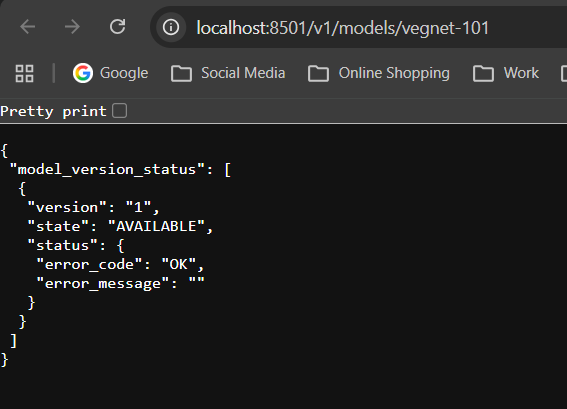

Figure 2.2: Local model status for VegNet-23.

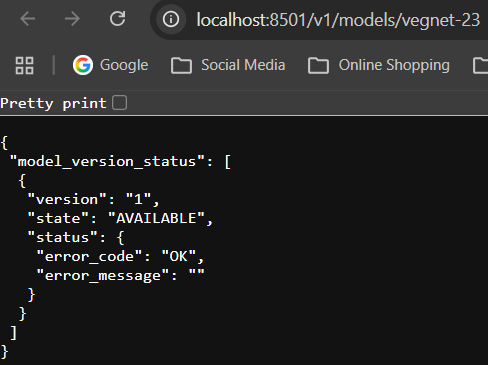

## 2.2 Local Predictions via HTTP


This section sends sample images to the local TensorFlow Serving endpoint and reports top-3 class probabilities.

Preprocessing is required because the models were trained on grayscale, normalized inputs of fixed size:
- EXIF transpose and grayscale conversion.
- Resize to the model input size (101x101 or 23x23).
- Normalize to [0, 1] and send JSON payload to `/v1/models/{model_name}:predict`.
- Parse the probability vector and display the top-3 classes.


VegNet-101 (Local TF Serving)


True Class,Image,Top-3 Predictions
Bean,,Bean: 1.000Cabbage: 0.000Cucumber and Bottle_Gourd: 0.000
Bitter_Gourd,,Bitter_Gourd: 1.000Cauliflower and Broccoli: 0.000Pumpkin: 0.000
Brinjal,,Brinjal: 0.926Bitter_Gourd: 0.072Radish and Carrot: 0.001
Cabbage,,Cabbage: 1.000Bean: 0.000Cucumber and Bottle_Gourd: 0.000
Capsicum,,Capsicum: 1.000Tomato: 0.000Pumpkin: 0.000
Cauliflower and Broccoli,,Cauliflower and Broccoli: 1.000Bitter_Gourd: 0.000Cucumber and Bottle_Gourd: 0.000
Cucumber and Bottle_Gourd,,Cucumber and Bottle_Gourd: 0.998Bean: 0.001Brinjal: 0.000
Potato,,Potato: 0.518Cucumber and Bottle_Gourd: 0.252Radish and Carrot: 0.191
Pumpkin,,Pumpkin: 1.000Brinjal: 0.000Cabbage: 0.000
Radish and Carrot,,Radish and Carrot: 0.968Bean: 0.028Cucumber and Bottle_Gourd: 0.002

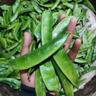
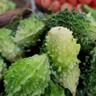
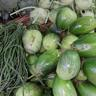
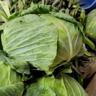
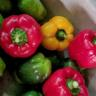
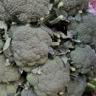
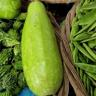
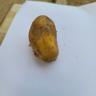
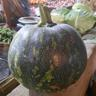
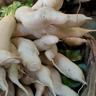
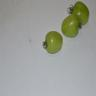

VegNet-23 (Local TF Serving)


True Class,Image,Top-3 Predictions
Bean,,Potato: 0.592Bean: 0.281Bitter_Gourd: 0.079
Bitter_Gourd,,Radish and Carrot: 0.479Cucumber and Bottle_Gourd: 0.428Tomato: 0.078
Brinjal,,Tomato: 0.907Potato: 0.066Brinjal: 0.014
Cabbage,,Cucumber and Bottle_Gourd: 0.713Capsicum: 0.218Radish and Carrot: 0.043
Capsicum,,Capsicum: 0.999Radish and Carrot: 0.001Potato: 0.000
Cauliflower and Broccoli,,Radish and Carrot: 0.713Bean: 0.133Tomato: 0.062
Cucumber and Bottle_Gourd,,Cucumber and Bottle_Gourd: 0.999Radish and Carrot: 0.001Capsicum: 0.000
Potato,,Radish and Carrot: 0.821Potato: 0.167Bean: 0.008
Pumpkin,,Potato: 0.983Brinjal: 0.013Capsicum: 0.004
Radish and Carrot,,Radish and Carrot: 0.997Bean: 0.003Tomato: 0.000

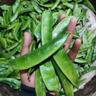
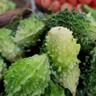
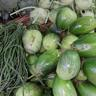
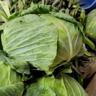
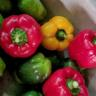
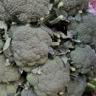
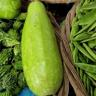
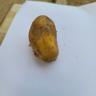
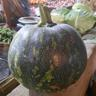
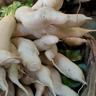
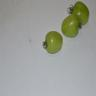

In [5]:
import requests
import time


def request_with_retry(method, url, max_attempts=5, backoff=2, **kwargs):
    for attempt in range(1, max_attempts + 1):
        try:
            response = requests.request(method, url, **kwargs)
            if response.status_code in (502, 503, 504):
                response.close()
                raise requests.exceptions.RequestException(
                    f"HTTP {response.status_code} from {url}"
                )
            return response
        except requests.exceptions.RequestException:
            if attempt == max_attempts:
                raise
            time.sleep(backoff)
            backoff = min(backoff * 2, 10)


def preprocess_image(path, target_size):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)
    img = ImageOps.grayscale(img)
    img = img.resize((target_size, target_size))
    arr = np.asarray(img, dtype=np.float32) / 255.0
    arr = np.expand_dims(arr, axis=-1)
    return np.expand_dims(arr, axis=0)


def wait_for_model_ready(base_url, model_name, timeout=120, interval=3):
    status_url = f"{base_url}/v1/models/{model_name}"
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            response = request_with_retry(
                "GET",
                status_url,
                max_attempts=2,
                timeout=10,
            )
            if response.ok:
                try:
                    payload = response.json()
                except ValueError:
                    payload = {}
                statuses = payload.get("model_version_status", [])
                if statuses and statuses[0].get("state") == "AVAILABLE":
                    return
        except requests.exceptions.RequestException:
            pass
        time.sleep(interval)
    raise TimeoutError(
        f"Timed out waiting for {status_url}. Check the TF Serving container/logs."
    )


def predict_tf_serving(base_url, model_name, image_path, input_size):
    payload = {"instances": preprocess_image(image_path, input_size).tolist()}
    response = request_with_retry(
        "POST",
        f"{base_url}/v1/models/{model_name}:predict",
        json=payload,
        timeout=30,
    )
    response.raise_for_status()
    probs = np.array(response.json()["predictions"][0])
    top_idx = np.argsort(probs)[::-1][:3]
    return [
        (classes[int(idx)], float(probs[int(idx)]))
        for idx in top_idx
    ]


def image_to_base64(path, size=96):
    img = Image.open(path).convert("RGB")
    img.thumbnail((size, size))
    buffer = io.BytesIO()
    img.save(buffer, format="JPEG")
    return base64.b64encode(buffer.getvalue()).decode("utf-8")


def build_table(results):
    rows = ""
    for row in results:
        preds_html = "<br>".join(
            [f"{label}: {conf:.3f}" for label, conf in row["top3"]]
        )
        rows += (
            "<tr>"
            f"<td>{row['true_label']}</td>"
            f"<td><img src='data:image/jpeg;base64,{row['img']}' width='96'/></td>"
            f"<td>{preds_html}</td>"
            "</tr>"
        )
    table = (
        "<table border='1' cellpadding='6' cellspacing='0'>"
        "<tr><th>True Class</th><th>Image</th><th>Top-3 Predictions</th></tr>"
        f"{rows}</table>"
    )
    display(HTML(table))


base_url = "http://127.0.0.1:8501"

wait_for_model_ready(base_url, "vegnet-101")
wait_for_model_ready(base_url, "vegnet-23")

sample_by_class = {}
for label in classes:
    candidates = list((DATA_DIR / "test" / label).glob("*.jpg"))
    if candidates:
        sample_by_class[label] = candidates[0]

results_101 = []
for label, path in sample_by_class.items():
    top3 = predict_tf_serving(base_url, "vegnet-101", path, 101)
    results_101.append(
        {"true_label": label, "img": image_to_base64(path), "top3": top3}
    )

print("VegNet-101 (Local TF Serving)")
build_table(results_101)

results_23 = []
for label, path in sample_by_class.items():
    top3 = predict_tf_serving(base_url, "vegnet-23", path, 23)
    results_23.append(
        {"true_label": label, "img": image_to_base64(path), "top3": top3}
    )

print("VegNet-23 (Local TF Serving)")
build_table(results_23)


The tables displayed below constitute Figure 2.3 (VegNet-101 local predictions) and Figure 2.4 (VegNet-23 local predictions). If no tables appear, verify the container is running and the endpoint is reachable.


## 2.3 Wrap Up with Dockerfile
The Dockerfile packages `tf_models` into a `tensorflow/serving` image and reads `models.config` to load both models.

Build from the repo root so `tf_models/` and `model_serving/models.config` are in the build context:

```bash
docker build -f model_serving/Dockerfile -t vegnet-serving .
docker run -p 8501:8501 vegnet-serving
```


## 3.1 Deploy to Render (Single Service for Both Models)
This section documents a single Render Web Service that serves both models via `models.config`.

Steps:
1. Push source code to GitHub (use LFS only if large model binaries are added later).
2. Create **one** Render Web Service using the provided Dockerfile.
3. Render settings:
   - Environment: **Docker**
   - Root Directory: repo root (leave blank)
   - Dockerfile Path: `model_serving/Dockerfile`
   - Branch: `main`
4. Verify deployment (same base URL, different model names):
   - https://ca2-daaa2b02-p2415691-gohkunming.onrender.com/v1/models/vegnet-101
   - https://ca2-daaa2b02-p2415691-gohkunming.onrender.com/v1/models/vegnet-23

Figure 3.1: Render service status showing deployment.
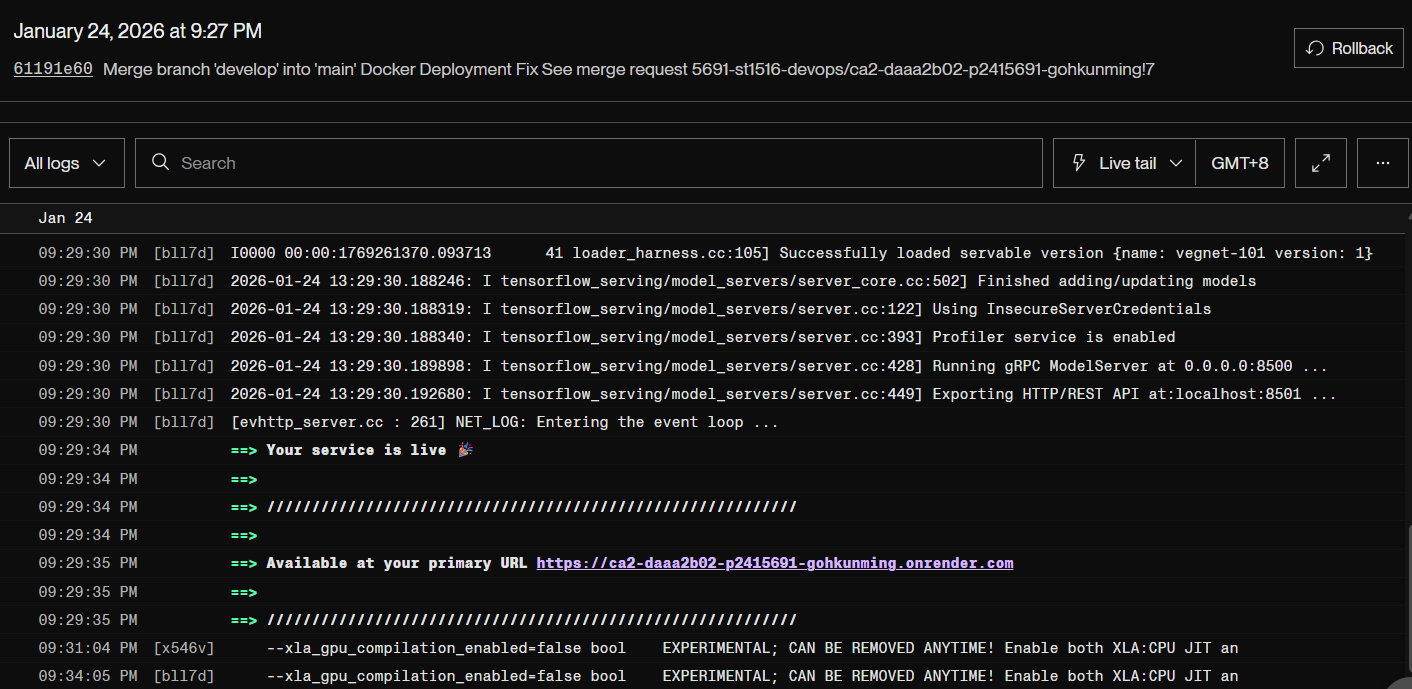

Figure 3.2: Render service status showing model endpoint for 101px by 101px model.
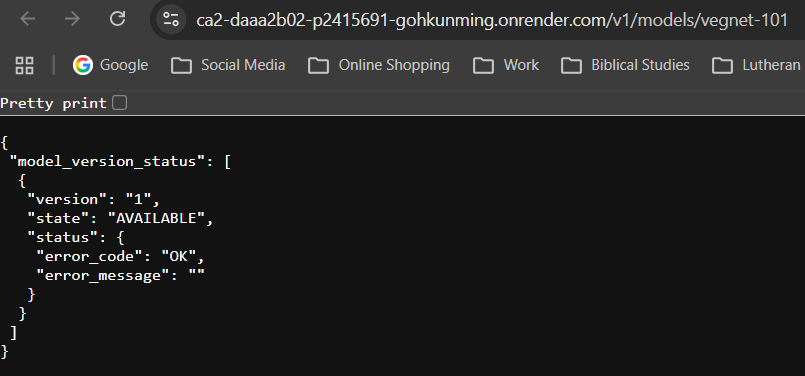

Figure 3.3: Render service status showing model endpoint for 23px by 23px model.
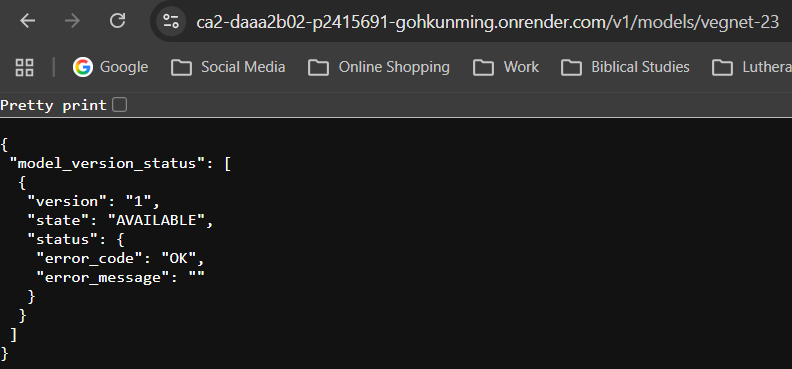


## 3.2 Render Predictions (Across Classes)


This section queries the Render endpoint and runs inference for both VegNet-101 and VegNet-23 using the same base URL.


vegnet-101 (Render TF Serving)


True Class,Image,Top-3 Predictions
Bean,,Bean: 1.000Cabbage: 0.000Cucumber and Bottle_Gourd: 0.000
Bitter_Gourd,,Bitter_Gourd: 1.000Cauliflower and Broccoli: 0.000Pumpkin: 0.000
Brinjal,,Brinjal: 0.926Bitter_Gourd: 0.072Radish and Carrot: 0.001
Cabbage,,Cabbage: 1.000Bean: 0.000Cucumber and Bottle_Gourd: 0.000
Capsicum,,Capsicum: 1.000Tomato: 0.000Pumpkin: 0.000
Cauliflower and Broccoli,,Cauliflower and Broccoli: 1.000Bitter_Gourd: 0.000Cucumber and Bottle_Gourd: 0.000
Cucumber and Bottle_Gourd,,Cucumber and Bottle_Gourd: 0.998Bean: 0.001Brinjal: 0.000
Potato,,Potato: 0.518Cucumber and Bottle_Gourd: 0.252Radish and Carrot: 0.191
Pumpkin,,Pumpkin: 1.000Brinjal: 0.000Cabbage: 0.000
Radish and Carrot,,Radish and Carrot: 0.968Bean: 0.028Cucumber and Bottle_Gourd: 0.002

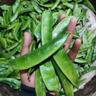
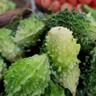
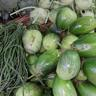
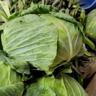
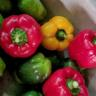
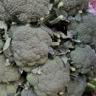
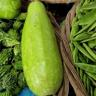
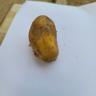
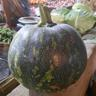
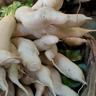
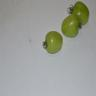

vegnet-23 (Render TF Serving)


True Class,Image,Top-3 Predictions
Bean,,Potato: 0.592Bean: 0.281Bitter_Gourd: 0.079
Bitter_Gourd,,Radish and Carrot: 0.479Cucumber and Bottle_Gourd: 0.428Tomato: 0.078
Brinjal,,Tomato: 0.907Potato: 0.066Brinjal: 0.014
Cabbage,,Cucumber and Bottle_Gourd: 0.713Capsicum: 0.218Radish and Carrot: 0.043
Capsicum,,Capsicum: 0.999Radish and Carrot: 0.001Potato: 0.000
Cauliflower and Broccoli,,Radish and Carrot: 0.713Bean: 0.133Tomato: 0.062
Cucumber and Bottle_Gourd,,Cucumber and Bottle_Gourd: 0.999Radish and Carrot: 0.001Capsicum: 0.000
Potato,,Radish and Carrot: 0.821Potato: 0.166Bean: 0.008
Pumpkin,,Potato: 0.983Brinjal: 0.013Capsicum: 0.004
Radish and Carrot,,Radish and Carrot: 0.997Bean: 0.003Tomato: 0.000

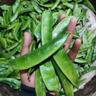
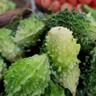
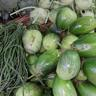
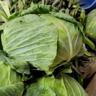
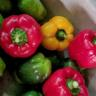
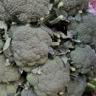
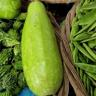
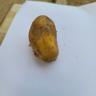
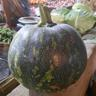
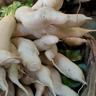
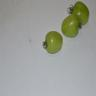

In [6]:
render_url_base = "https://ca2-daaa2b02-p2415691-gohkunming.onrender.com"

render_url_101 = render_url_base
render_url_23 = render_url_base

wait_for_model_ready(render_url_101, "vegnet-101")
wait_for_model_ready(render_url_23, "vegnet-23")

results_render_101 = []
for label, path in sample_by_class.items():
    top3 = predict_tf_serving(render_url_101, "vegnet-101", path, 101)
    results_render_101.append(
        {"true_label": label, "img": image_to_base64(path), "top3": top3}
    )

print("vegnet-101 (Render TF Serving)")
build_table(results_render_101)

results_render_23 = []
for label, path in sample_by_class.items():
    top3 = predict_tf_serving(render_url_23, "vegnet-23", path, 23)
    results_render_23.append(
        {"true_label": label, "img": image_to_base64(path), "top3": top3}
    )

print("vegnet-23 (Render TF Serving)")
build_table(results_render_23)


The tables displayed below constitute Figure 3.3 (VegNet-101 Render predictions) and Figure 3.4 (VegNet-23 Render predictions).


# 4 Overall Documentation
1. **SavedModel export**
   - Evidence: Section 2 output confirming `saved_model.pb` and `variables/` for both models.
2. **Local serving verification**
   - Evidence: Figure 2.1 and Figure 2.2 (model status) and Figure 2.3 and Figure 2.4 (local prediction tables).
3. **Render deployment**
   - Evidence: Figure 3.1 and Figure 3.2 (deploy logs and service status).
4. **Render inference verification**
   - Evidence: Figure 3.3 and Figure 3.4 (Render prediction tables).
5. **Status endpoints (JSON)**
   - Local:
     - http://localhost:8501/v1/models/vegnet-101
     - http://localhost:8501/v1/models/vegnet-23
   - Render:
     - https://ca2-daaa2b02-p2415691-gohkunming.onrender.com/v1/models/vegnet-101
     - https://ca2-daaa2b02-p2415691-gohkunming.onrender.com/v1/models/vegnet-23

Example JSON (status check):
```json
{
  "model_version_status": [
    {
      "version": "1",
      "state": "AVAILABLE",
      "status": {
        "error_code": "OK",
        "error_message": ""
      }
    }
  ]
}
```
